# Investigação do `olist_orders_dataset`

Este notebook faz uma análise exploratória dos pedidos do Olist, combinando estatísticas descritivas, qualidade dos dados, análise temporal e um relatório automático com `ydata-profiling`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)

# Permite executar o notebook tanto a partir da raiz do projeto quanto de notebooks/.
candidatos_raiz = [Path.cwd(), Path.cwd().parent]
PROJ_ROOT = next(path for path in candidatos_raiz if (path / "data/raw").exists())
DATA_PATH = PROJ_ROOT / "data/raw/olist_orders_dataset.csv"
REPORT_PATH = PROJ_ROOT / "reports/olist_orders_profile.html"
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)

DATE_COLUMNS = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders = pd.read_csv(DATA_PATH, parse_dates=DATE_COLUMNS)
print(f"Arquivo: {DATA_PATH.relative_to(PROJ_ROOT)}")
print(f"Dimensões: {orders.shape[0]:,} linhas x {orders.shape[1]} colunas")

Arquivo: data/raw/olist_orders_dataset.csv
Dimensões: 99,441 linhas x 8 colunas


## 1. Visão geral e qualidade dos dados

In [2]:
display(orders.head())
display(orders.dtypes.rename("tipo").to_frame())

resumo_qualidade = pd.DataFrame({
    "tipo": orders.dtypes.astype(str),
    "nulos": orders.isna().sum(),
    "% nulos": (orders.isna().mean() * 100).round(2),
    "valores únicos": orders.nunique(dropna=False),
})
display(resumo_qualidade)
print(f"Linhas duplicadas: {orders.duplicated().sum():,}")
print(f"order_id duplicados: {orders['order_id'].duplicated().sum():,}")
display(orders["order_status"].value_counts(dropna=False).rename_axis("status").to_frame("pedidos"))

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


,tipo
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


,tipo,nulos,% nulos,valores únicos
order_id,object,0,0.00,99441
customer_id,object,0,0.00,99441
order_status,object,0,0.00,8
order_purchase_timestamp,datetime64[ns],0,0.00,98875
order_approved_at,datetime64[ns],160,0.16,90734
order_delivered_carrier_date,datetime64[ns],1783,1.79,81019
order_delivered_customer_date,datetime64[ns],2965,2.98,95665
order_estimated_delivery_date,datetime64[ns],0,0.00,459


Linhas duplicadas: 0
order_id duplicados: 0


,pedidos
status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


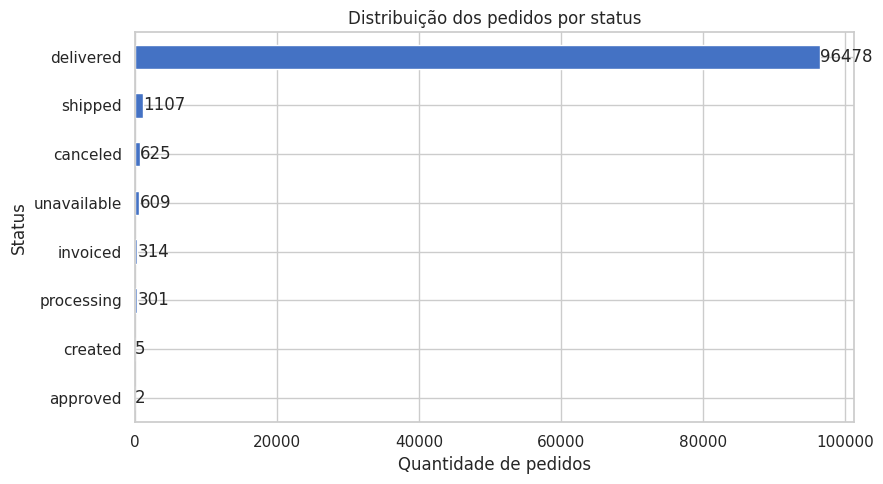

In [3]:
status = orders["order_status"].value_counts().sort_values()
ax = status.plot(kind="barh", figsize=(9, 5), color="#4472C4")
ax.set(title="Distribuição dos pedidos por status", xlabel="Quantidade de pedidos", ylabel="Status")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.show()

## 2. As seis dimensões da qualidade dos dados

A análise abaixo considera somente o olist_orders_dataset. Começamos pela unicidade e usamos Pandera para validar a estrutura, os identificadores, os status e os tipos das datas.

In [4]:
import pandera.pandas as pa

ALLOWED_STATUSES = {
    "approved", "canceled", "created", "delivered",
    "invoiced", "processing", "shipped", "unavailable",
}

orders_schema = pa.DataFrameSchema(
    {
        "order_id": pa.Column(
            str,
            checks=pa.Check.str_matches(r"^[0-9a-f]{32}$"),
            unique=True,
            nullable=False,
        ),
        "customer_id": pa.Column(
            str,
            checks=pa.Check.str_matches(r"^[0-9a-f]{32}$"),
            nullable=False,
        ),
        "order_status": pa.Column(
            str, checks=pa.Check.isin(ALLOWED_STATUSES), nullable=False
        ),
        "order_purchase_timestamp": pa.Column(pa.DateTime, nullable=False),
        "order_approved_at": pa.Column(pa.DateTime, nullable=True),
        "order_delivered_carrier_date": pa.Column(pa.DateTime, nullable=True),
        "order_delivered_customer_date": pa.Column(pa.DateTime, nullable=True),
        "order_estimated_delivery_date": pa.Column(pa.DateTime, nullable=False),
    },
    strict=True,
    coerce=False,
)

# 1. Unicidade: order_id é a chave do pedido; customer_id pode se repetir.
unicidade = pd.Series({
    "linhas duplicadas integralmente": orders.duplicated().sum(),
    "order_id duplicados": orders["order_id"].duplicated().sum(),
    "order_id nulos": orders["order_id"].isna().sum(),
    "clientes distintos": orders["customer_id"].nunique(),
    "pedidos do cliente mais frequente": orders["customer_id"].value_counts().max(),
})
display(unicidade.rename("quantidade").to_frame())

# 2. Completude: campos essenciais não podem estar nulos.
required_columns = [
    "order_id", "customer_id", "order_status",
    "order_purchase_timestamp", "order_estimated_delivery_date",
]
completude = pd.DataFrame({
    "nulos": orders.isna().sum(),
    "% nulos": (orders.isna().mean() * 100).round(2),
    "campo essencial": orders.columns.isin(required_columns),
})
display(completude)

# 3. Consistência: regras temporais e compatibilidade entre status e datas.
consistencia = pd.Series({
    "aprovação antes da compra": (orders["order_approved_at"] < orders["order_purchase_timestamp"]).sum(),
    "transportadora antes da aprovação": (orders["order_delivered_carrier_date"] < orders["order_approved_at"]).sum(),
    "entrega antes da transportadora": (orders["order_delivered_customer_date"] < orders["order_delivered_carrier_date"]).sum(),
    "entregues sem data de entrega": ((orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()).sum(),
    "não entregues com data de entrega": ((orders["order_status"] != "delivered") & orders["order_delivered_customer_date"].notna()).sum(),
})
display(consistencia.rename("ocorrências").to_frame())

# 4. Atualidade: útil para histórico, mas não para representar pedidos atuais.
ultima_compra = orders["order_purchase_timestamp"].max()
atualidade = pd.Series({
    "primeira compra": orders["order_purchase_timestamp"].min(),
    "última compra": ultima_compra,
    "última estimativa": orders["order_estimated_delivery_date"].max(),
    "idade do último pedido (dias)": (pd.Timestamp.now() - ultima_compra).days,
})
display(atualidade.rename("valor").to_frame())

# 5. Validade: Pandera valida formato, tipo, domínio, nulos e chave única.
orders_schema.validate(orders, lazy=True)
print("Validade Pandera: aprovada")

# 6. Acurácia: sem fonte externa, usamos plausibilidade temporal como proxy.
regras_temporais = {
    "aprovação após compra": orders["order_approved_at"].isna() | (orders["order_approved_at"] >= orders["order_purchase_timestamp"]),
    "transportadora após aprovação": orders["order_delivered_carrier_date"].isna() | orders["order_approved_at"].isna() | (orders["order_delivered_carrier_date"] >= orders["order_approved_at"]),
    "entrega após transportadora": orders["order_delivered_customer_date"].isna() | orders["order_delivered_carrier_date"].isna() | (orders["order_delivered_customer_date"] >= orders["order_delivered_carrier_date"]),
}
acuracia_proxy = pd.Series({nome: regra.mean() * 100 for nome, regra in regras_temporais.items()})
display(acuracia_proxy.rename("% de registros plausíveis").to_frame().round(2))
print("Acurácia absoluta exige uma fonte externa de verdade; estes são apenas proxies internos.")

,quantidade
linhas duplicadas integralmente,0
order_id duplicados,0
order_id nulos,0
clientes distintos,99441
pedidos do cliente mais frequente,1


,nulos,% nulos,campo essencial
order_id,0,0.00,True
customer_id,0,0.00,True
order_status,0,0.00,True
order_purchase_timestamp,0,0.00,True
order_approved_at,160,0.16,False
order_delivered_carrier_date,1783,1.79,False
order_delivered_customer_date,2965,2.98,False
order_estimated_delivery_date,0,0.00,True


,ocorrências
aprovação antes da compra,0
transportadora antes da aprovação,1359
entrega antes da transportadora,23
entregues sem data de entrega,8
não entregues com data de entrega,6


,valor
primeira compra,2016-09-04 21:15:19
última compra,2018-10-17 17:30:18
última estimativa,2018-11-12 00:00:00
idade do último pedido (dias),2858


Validade Pandera: aprovada


,% de registros plausíveis
aprovação após compra,100.00
transportadora após aprovação,98.63
entrega após transportadora,99.98


Acurácia absoluta exige uma fonte externa de verdade; estes são apenas proxies internos.


## 2. Relatório automático com `ydata-profiling`

O relatório complementa a análise manual com distribuições, cardinalidade, nulos, duplicidades, correlações e possíveis valores extremos. `minimal=True` mantém a execução adequada para o tamanho deste dataset.

In [5]:
from ydata_profiling import ProfileReport

profile = ProfileReport(
    orders,
    title="Perfil exploratório — Olist Orders",
    explorative=True,
    minimal=True,
)
profile.to_file(REPORT_PATH)
print(f"Relatório salvo em: {REPORT_PATH.relative_to(PROJ_ROOT)}")

/workspaces/MLsample/olist/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/tmp/ipykernel_30392/1196029441.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport
Export report to file: 100%|██████████| 1/1 [00:00<00:00, 269.87it/s]

Relatório salvo em: reports/olist_orders_profile.html


## 3. Evolução temporal dos pedidos

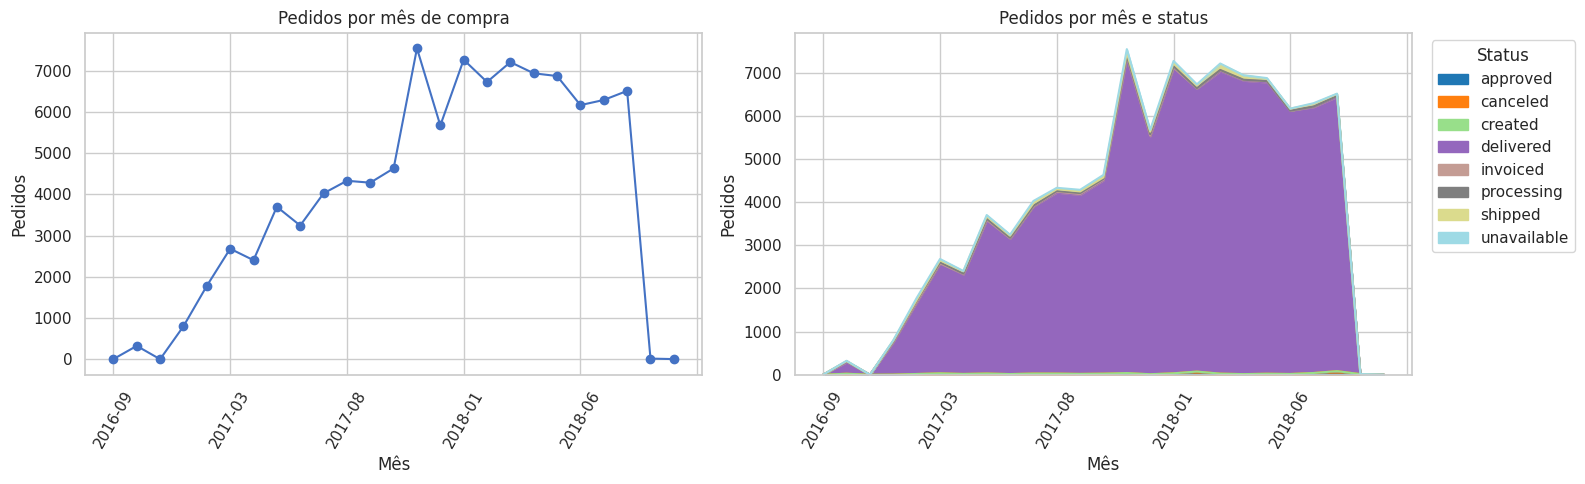

Período de compra: 2016-09-04 21:15:19 a 2018-10-17 17:30:18


In [6]:
orders["purchase_month"] = orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
monthly_orders = orders.groupby("purchase_month").size()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
monthly_orders.plot(ax=axes[0], marker="o", color="#4472C4")
axes[0].set(title="Pedidos por mês de compra", xlabel="Mês", ylabel="Pedidos")
axes[0].tick_params(axis="x", rotation=60)

status_month = pd.crosstab(orders["purchase_month"], orders["order_status"])
status_month.plot.area(ax=axes[1], stacked=True, colormap="tab20")
axes[1].set(title="Pedidos por mês e status", xlabel="Mês", ylabel="Pedidos")
axes[1].tick_params(axis="x", rotation=60)
axes[1].legend(title="Status", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Período de compra:", orders["order_purchase_timestamp"].min(), "a", orders["order_purchase_timestamp"].max())

## 4. Prazos, atrasos e consistência temporal

Os intervalos abaixo são calculados em dias. Para avaliar o prazo de entrega, são considerados apenas pedidos entregues e com as datas necessárias preenchidas.

,valor
pedidos entregues,96478.00
entrega mediana (dias),7.10
entrega média (dias),9.33
atraso mediano vs. estimativa (dias),-11.95
% entregues no prazo,91.88


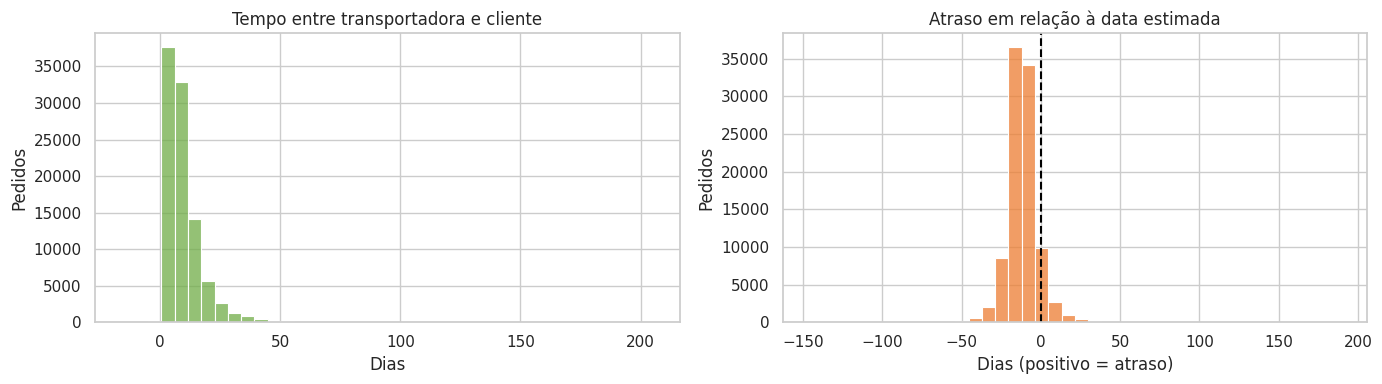

In [7]:
orders["approval_hours"] = (
    orders["order_approved_at"] - orders["order_purchase_timestamp"]
).dt.total_seconds() / 3600
orders["shipping_days"] = (
    orders["order_delivered_carrier_date"] - orders["order_approved_at"]
).dt.total_seconds() / 86400
orders["delivery_days"] = (
    orders["order_delivered_customer_date"] - orders["order_delivered_carrier_date"]
).dt.total_seconds() / 86400
orders["estimated_delay_days"] = (
    orders["order_delivered_customer_date"] - orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

entregues = orders[orders["order_status"] == "delivered"]
metricas_prazo = pd.Series({
    "pedidos entregues": len(entregues),
    "entrega mediana (dias)": entregues["delivery_days"].median(),
    "entrega média (dias)": entregues["delivery_days"].mean(),
    "atraso mediano vs. estimativa (dias)": entregues["estimated_delay_days"].median(),
    "% entregues no prazo": (entregues["estimated_delay_days"] <= 0).mean() * 100,
})
display(metricas_prazo.to_frame("valor").round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=entregues, x="delivery_days", bins=40, ax=axes[0], color="#70AD47")
axes[0].set(title="Tempo entre transportadora e cliente", xlabel="Dias", ylabel="Pedidos")
sns.histplot(data=entregues, x="estimated_delay_days", bins=40, ax=axes[1], color="#ED7D31")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set(title="Atraso em relação à data estimada", xlabel="Dias (positivo = atraso)", ylabel="Pedidos")
plt.tight_layout()
plt.show()

In [8]:
# Verificações de ordem cronológica; NaN não é marcado como inconsistência.
consistencias = pd.Series({
"aprovação antes da compra": (orders["order_approved_at"] < orders["order_purchase_timestamp"]).sum(),
"transportadora antes da aprovação": (orders["order_delivered_carrier_date"] < orders["order_approved_at"]).sum(),
"entrega ao cliente antes da transportadora": (orders["order_delivered_customer_date"] < orders["order_delivered_carrier_date"]).sum(),
"entregues sem data de entrega ao cliente": ((orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()).sum(),
"não entregues com data de entrega ao cliente": ((orders["order_status"] != "delivered") & orders["order_delivered_customer_date"].notna()).sum(),
})
display(consistencias.rename("ocorrências").to_frame())

print("Status sem data de entrega ao cliente:")
display(pd.crosstab(orders["order_status"], orders["order_delivered_customer_date"].isna(), normalize="index").round(3))

,ocorrências
aprovação antes da compra,0
transportadora antes da aprovação,1359
entrega ao cliente antes da transportadora,23
entregues sem data de entrega ao cliente,8
não entregues com data de entrega ao cliente,6


Status sem data de entrega ao cliente:


order_delivered_customer_date,False,True
order_status,,
approved,0.00,1.00
canceled,0.01,0.99
created,0.00,1.00
delivered,1.00,0.00
invoiced,0.00,1.00
processing,0.00,1.00
shipped,0.00,1.00
unavailable,0.00,1.00


## 5. Principais achados

Após executar todas as células, registrar aqui os achados observados no perfil e nos gráficos. Como ponto de partida, o dataset possui forte concentração em pedidos `delivered`, valores ausentes nas etapas posteriores do fluxo e datas que permitem medir atraso e tempo de entrega.